# Tutorial 8: The Numerical Crime: Numerical Diffusion and the Discrete Adjoint

**Question.** We observe a wave pulse after it has travelled for a while and want to recover how it looked at the start (its amplitude and width). The forward model is the simplest wave solver there is: the first-order upwind scheme for $u_t + c\,u_x = 0$.

Two things go wrong, and this tutorial is about both:

1. **The solver is not the physics.** Upwind adds *numerical diffusion*, and counter-intuitively it adds **more of it when you lower the CFL number**. The inversion does not complain; it quietly absorbs the smearing into the parameters and returns a confidently wrong answer.
2. **We can hide the problem from ourselves.** If the "measurements" are produced by the same scheme we invert with (the *inverse crime*), the recovery looks perfect at every CFL number.

We then use a hand-written **discrete adjoint** to get exact gradients, verify it, and see which fixes actually remove the bias.

**You will learn**

- the modified equation of upwind and why its diffusion is $\nu=\tfrac12 c\,\Delta x\,(1-\mathrm{CFL})$;
- why a smaller time step makes the smearing *worse*;
- the inverse crime, and how to avoid committing it;
- the adjoint of a linear time-stepping scheme is just the transposed scheme run backwards;
- how to test an adjoint (dot-product test, finite-difference check).

Only NumPy, SciPy and Matplotlib are needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. Forward problem: linear advection on a periodic domain

$$u_t + c\,u_x = 0,\qquad x\in[0,1)\ \text{periodic},\qquad u(x,0)=u_0(x).$$

The exact solution is a pure translation, $u(x,t)=u_0(x-ct)$. Nothing is lost, nothing is smeared.

Our unknown is a Gaussian initial pulse with two parameters $\theta=(A,w)$:

$$u_0(x;\theta)=A\exp\!\Big(-\frac{(x-x_0)^2}{2w^2}\Big).$$

We take $c=1$, final time $T=0.5$, so the pulse moves from $x_0=0.25$ to $0.75$. The true values are $A=1$, $w=0.08$.

In [2]:
c, T = 1.0, 0.5
nx = 100
L = 1.0
dx = L / nx
x = (np.arange(nx) + 0.5) * dx
x0 = 0.25

def per(d):                       # signed periodic distance
    return (d + L/2) % L - L/2

def gauss(x, A, w, centre=x0):
    return A * np.exp(-0.5 * (per(x - centre) / w)**2)

A_true, w_true = 1.0, 0.08
u0_true = gauss(x, A_true, w_true)
u_exact = gauss(x, A_true, w_true, x0 + c*T)      # exact solution at T

## 2. The solver: a linear stencil

Every scheme in this tutorial has the form

$$u_i^{n+1}= a_{-1}\,u_{i-1}^{n}+a_0\,u_i^{n}+a_{+1}\,u_{i+1}^{n},\qquad \mathrm{CFL}=\frac{c\,\Delta t}{\Delta x}.$$

| scheme | $a_{-1}$ | $a_0$ | $a_{+1}$ | order |
|---|---|---|---|---|
| upwind | CFL | $1-$CFL | 0 | 1 |
| Lax-Wendroff | $\tfrac12$CFL(1+CFL) | $1-$CFL$^2$ | $-\tfrac12$CFL(1-CFL) | 2 |

We fix the final time $T$ and choose the number of steps $n$, so $\Delta t=T/n$ and **a smaller CFL simply means more steps**. That is how a user lowers the CFL number in practice (a smaller, "safer" time step).

In [3]:
def n_steps(cfl_target):
    return int(np.ceil(c * T / (cfl_target * dx)))

def coeffs(cfl, scheme):
    if scheme == "upwind":
        return cfl, 1 - cfl, 0.0
    if scheme == "lw":
        return 0.5*cfl*(1 + cfl), 1 - cfl**2, -0.5*cfl*(1 - cfl)
    raise ValueError(scheme)

def forward(u0, n, scheme="upwind"):
    cfl = c * (T / n) / dx
    am, a0, ap = coeffs(cfl, scheme)
    u = u0.copy()
    for _ in range(n):
        u = am*np.roll(u, 1) + a0*u + ap*np.roll(u, -1)
    return u

## 3. The crime scene: smearing grows as the CFL number drops

Run upwind on the true pulse for several CFL numbers and compare with the exact (translated) solution.

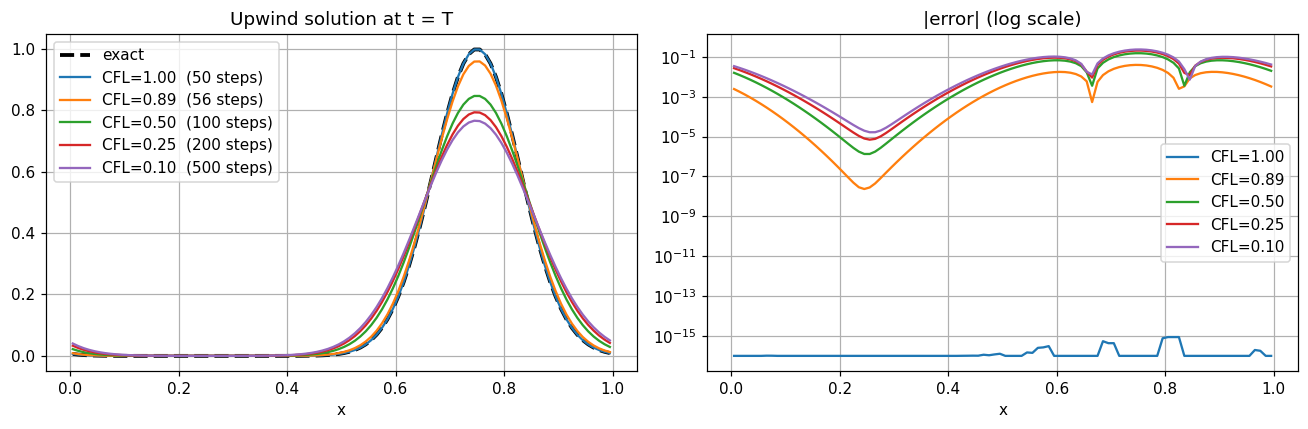

In [4]:
cfls = [1.0, 0.9, 0.5, 0.25, 0.1]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x, u_exact, "k--", lw=2.5, label="exact")
for ct in cfls:
    n = n_steps(ct)
    u = forward(u0_true, n)
    ax[0].plot(x, u, label=f"CFL={c*(T/n)/dx:.2f}  ({n} steps)")
ax[0].set_title("Upwind solution at t = T"); ax[0].set_xlabel("x"); ax[0].legend()

for ct in cfls:
    n = n_steps(ct)
    u = forward(u0_true, n)
    ax[1].semilogy(x, np.abs(u - u_exact) + 1e-16, label=f"CFL={c*(T/n)/dx:.2f}")
ax[1].set_title("|error| (log scale)"); ax[1].set_xlabel("x"); ax[1].legend()
plt.tight_layout(); plt.show()

CFL = 1 reproduces the exact solution to round-off (the scheme is then a pure shift). Every lower CFL smears the pulse more, and **the smallest CFL is the worst**.

### Why? The modified equation

Taylor-expand the upwind update. The scheme does not solve $u_t+cu_x=0$ but, to leading order,

$$u_t + c\,u_x \;=\; \nu\,u_{xx},\qquad \nu=\frac{c\,\Delta x}{2}\,(1-\mathrm{CFL}).$$

This is an advection-*diffusion* equation, with a diffusion coefficient we never asked for. At fixed $\Delta x$ and $T$:

- CFL $=1$: $\nu=0$.
- CFL $\to 0$: $\nu\to c\Delta x/2$, the maximum. Each step adds a little blur, and a small CFL needs *many* steps. The diffusion per unit **time** does not shrink as $\Delta t\to0$; it saturates.

A Gaussian under diffusion stays Gaussian with $w^2\to w^2+2\nu T$. Check the prediction:

In [5]:
def fit_width(u):
    # width from the second moment about the (periodic) peak
    i = np.argmax(u)
    d = per(x - x[i]); m = u.sum()
    return np.sqrt(np.sum(u * d**2) / m)

print(f"{'CFL':>6} {'steps':>6} {'width (run)':>12} {'width (modified eq.)':>22}")
for ct in cfls:
    n = n_steps(ct); cfl = c*(T/n)/dx
    nu = 0.5*c*dx*(1 - cfl)
    w_pred = np.sqrt(w_true**2 + 2*nu*T)
    print(f"{cfl:6.3f} {n:6d} {fit_width(forward(u0_true, n)):12.4f} {w_pred:22.4f}")

   CFL  steps  width (run)   width (modified eq.)
 1.000     50       0.0802                 0.0800
 0.893     56       0.0834                 0.0833
 0.500    100       0.0945                 0.0943
 0.250    200       0.1009                 0.1007
 0.100    500       0.1045                 0.1044


The measured widths match the modified-equation prediction to three digits. At CFL = 0.1 the pulse has broadened from 0.08 to about 0.104 purely because of the scheme, and its peak has dropped by a factor of about 0.77.

## 4. The inverse problem

**Data:** $d = u(x,T)$ on the grid. **Unknowns:** $\theta=(A,w)$. **Misfit:**

$$J(\theta)=\tfrac12\,\Delta x\sum_i\big(u_i^{N}(\theta)-d_i\big)^2 .$$

To minimise $J$ with a gradient method we need $\nabla_\theta J$. Finite differences work for two parameters, but the point of the adjoint is that it also works when the unknown is the whole initial field with $10^3$ or $10^6$ values.

### The discrete adjoint

One time step is a linear map $u^{n+1}=M u^n$, so $u^N=M^N u^0$ and

$$J=\tfrac12\Delta x\,\|M^N u^0-d\|^2\;\Rightarrow\;\frac{\partial J}{\partial u^0}=(M^{T})^N\big(\Delta x\,(u^N-d)\big).$$

So the adjoint run is: start from the residual, apply $M^T$ for $N$ steps. For our stencil, $M^T$ has the **mirrored** stencil: $\lambda^{n}_j=a_{-1}\lambda^{n+1}_{j+1}+a_0\lambda^{n+1}_j+a_{+1}\lambda^{n+1}_{j-1}$. Upwind information flows left to right; the adjoint information flows right to left, and the adjoint of upwind is *downwind*. Finally the chain rule gives
$\partial J/\partial A=\sum_i g_i\,G_i$ and $\partial J/\partial w=\sum_i g_i\,A\,G_i\,(x_i-x_0)^2/w^3$, where $g=\partial J/\partial u^0$ and $G_i=e^{-(x_i-x_0)^2/2w^2}$.

Because this is the exact transpose of the *discrete* scheme, the gradient is the exact gradient of the discrete $J$ (no continuous-adjoint approximation).

In [6]:
def adjoint(r, n, scheme="upwind"):
    # apply (M^T)^n to r : mirrored stencil
    cfl = c * (T / n) / dx
    am, a0, ap = coeffs(cfl, scheme)
    lam = r.copy()
    for _ in range(n):
        lam = am*np.roll(lam, -1) + a0*lam + ap*np.roll(lam, 1)
    return lam

def J_and_grad(theta, d, n, scheme="upwind"):
    A, w = theta
    u0 = gauss(x, A, w)
    r = forward(u0, n, scheme) - d
    J = 0.5 * dx * np.sum(r**2)
    g = adjoint(dx * r, n, scheme)                 # dJ/du0
    G = gauss(x, 1.0, w)
    dJ = np.array([np.sum(g * G),
                   np.sum(g * A * G * per(x - x0)**2 / w**3)])
    return J, dJ

### Testing an adjoint (do this every time)

**Dot-product test.** For any vectors $u,v$ we need $\langle Mu,v\rangle=\langle u,M^Tv\rangle$. This checks that `adjoint` really is the transpose of `forward`, independently of any objective. **Gradient check.** Compare with central finite differences.

In [7]:
rng = np.random.default_rng(0)
u, v = rng.standard_normal(nx), rng.standard_normal(nx)
for scheme in ["upwind", "lw"]:
    n = n_steps(0.5)
    lhs = np.dot(forward(u, n, scheme), v)
    rhs = np.dot(u, adjoint(v, n, scheme))
    print(f"{scheme:7s}  <Mu,v> = {lhs: .12f}   <u,M^T v> = {rhs: .12f}   diff = {abs(lhs-rhs):.1e}")

theta = np.array([0.7, 0.1]); n = n_steps(0.5)
J, g = J_and_grad(theta, u_exact, n)
h = 1e-6
fd = np.array([(J_and_grad(theta + h*e, u_exact, n)[0] -
                J_and_grad(theta - h*e, u_exact, n)[0]) / (2*h) for e in np.eye(2)])
print("\nadjoint gradient     :", g)
print("finite-diff gradient :", fd)
print("relative difference  :", np.linalg.norm(g - fd) / np.linalg.norm(fd))

upwind   <Mu,v> =  1.460190289313   <u,M^T v> =  1.460190289313   diff = 2.2e-16
lw       <Mu,v> =  7.240935813366   <u,M^T v> =  7.240935813366   diff = 1.8e-15

adjoint gradient     : [-0.0348903  -0.01475939]
finite-diff gradient : [-0.0348903  -0.01475939]
relative difference  : 5.742474987420198e-10


The dot-product test passes to round-off and the gradient matches finite differences to about 9 digits. We can trust the adjoint.

## 5. Experiment A: committing the inverse crime

Generate the data with **the same scheme and the same step count** we invert with, then fit.

In [8]:
def fit(d, n, scheme):
    res = minimize(J_and_grad, x0=[0.5, 0.15], args=(d, n, scheme), jac=True,
                   method="L-BFGS-B", bounds=[(0.1, 3.0), (0.01, 0.3)])
    return res.x

print(f"{'CFL':>6} | recovered (A, w)   [crime: data from same upwind scheme]")
for ct in cfls:
    n = n_steps(ct); cfl = c*(T/n)/dx
    d_crime = forward(u0_true, n, "upwind")
    A_r, w_r = fit(d_crime, n, "upwind")
    print(f"{cfl:6.3f} | A = {A_r:.4f}, w = {w_r:.4f}")

   CFL | recovered (A, w)   [crime: data from same upwind scheme]
 1.000 | A = 1.0000, w = 0.0800
 0.893 | A = 1.0000, w = 0.0800
 0.500 | A = 1.0000, w = 0.0800
 0.250 | A = 1.0000, w = 0.0800


 0.100 | A = 1.0000, w = 0.0800


Perfect recovery at every CFL number: $A=1$, $w=0.08$. A paper that only reported this table would conclude the method is flawless. But the data came out of the same smearing machine we invert, so the smearing cancels exactly. **The solver's error is invisible in this experiment.**

## 6. Experiment B: honest data

In a real experiment the pulse travels through physics, not through our scheme. Here the "physics" is the exact translated Gaussian `u_exact`. Fit the upwind model to it.

In [9]:
rows = []
for ct in cfls:
    n = n_steps(ct); cfl = c*(T/n)/dx
    A_r, w_r = fit(u_exact, n, "upwind")
    nu = 0.5*c*dx*(1 - cfl)
    w_pred = np.sqrt(max(w_true**2 - 2*nu*T, 1e-12))
    rows.append((cfl, A_r, w_r, w_pred))
    print(f"CFL={cfl:5.3f}:  A = {A_r:.4f} (true 1.0),  w = {w_r:.4f} (true 0.08),   predicted w = {w_pred:.4f}")
rows = np.array(rows)

CFL=1.000:  A = 1.0000 (true 1.0),  w = 0.0800 (true 0.08),   predicted w = 0.0800
CFL=0.893:  A = 1.0446 (true 1.0),  w = 0.0766 (true 0.08),   predicted w = 0.0766
CFL=0.500:  A = 1.2817 (true 1.0),  w = 0.0624 (true 0.08),   predicted w = 0.0624


CFL=0.250:  A = 1.5539 (true 1.0),  w = 0.0515 (true 0.08),   predicted w = 0.0515


CFL=0.100:  A = 1.8274 (true 1.0),  w = 0.0438 (true 0.08),   predicted w = 0.0436


Now the inversion is wrong, and wrong in a structured way. The recovered pulse is **narrower and taller** than the truth. The model will smear whatever we give it, so to land on the observed width it must start sharper. The area $A\,w$ is conserved by upwind, which is why the amplitude is biased upward.

The size of the bias is predicted by the modified equation: the recovered width satisfies $w_\text{rec}^2\approx w_\text{true}^2-2\nu T$ (last column). At CFL = 0.1 the amplitude comes out about 80% too high. The optimizer converged happily, and no residual tells you that anything is wrong. This is a *model error* absorbed into the parameters.

## 7. Fixes

Bias comes from the discretisation, so shrink the discretisation error rather than the noise. Three options:

1. **Use CFL close to 1** (works here only because the equation is linear with constant $c$; in general you can't).
2. **Use a higher-order scheme**, e.g. Lax-Wendroff. It has its own adjoint (check it with the dot-product test above).
3. **Refine the grid.** Upwind's $\nu\propto\Delta x$ shrinks only linearly.

Compare the recovered width for each:

In [10]:
def run_scheme(scheme, ct, nx_):
    global nx, dx, x, u_exact
    old = (nx, dx, x, u_exact)
    nx = nx_; dx = L/nx; x = (np.arange(nx) + 0.5)*dx
    u_exact = gauss(x, A_true, w_true, x0 + c*T)
    n = n_steps(ct)
    out = fit(u_exact, n, scheme)
    nx, dx, x, u_exact = old
    return out

print(f"{'config':<32} {'A':>8} {'w':>8}")
for label, scheme, ct, nx_ in [
    ("upwind, CFL 0.1, nx=100",   "upwind", 0.1, 100),
    ("upwind, CFL 0.1, nx=400",   "upwind", 0.1, 400),
    ("upwind, CFL 0.9, nx=100",   "upwind", 0.9, 100),
    ("Lax-Wendroff, CFL 0.1",     "lw",     0.1, 100),
    ("Lax-Wendroff, CFL 0.5",     "lw",     0.5, 100),
]:
    A_r, w_r = run_scheme(scheme, ct, nx_)
    print(f"{label:<32} {A_r:8.4f} {w_r:8.4f}")

config                                  A        w


upwind, CFL 0.1, nx=100            1.8274   0.0438


upwind, CFL 0.1, nx=400            1.1015   0.0726
upwind, CFL 0.9, nx=100            1.0446   0.0766
Lax-Wendroff, CFL 0.1              0.9993   0.0801
Lax-Wendroff, CFL 0.5              1.0007   0.0799


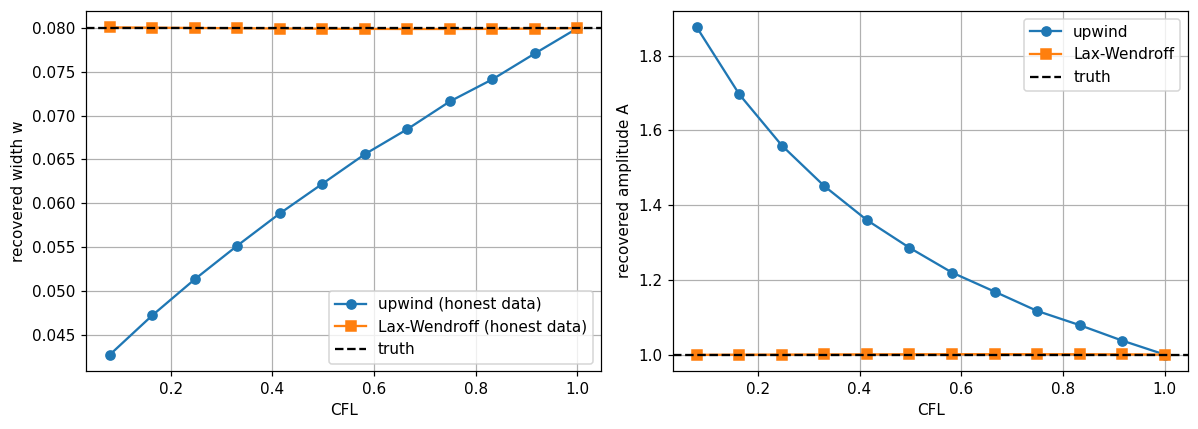

In [11]:
cf = np.linspace(0.08, 1.0, 12)
w_up, w_lw, A_up, A_lw = [], [], [], []
for ct in cf:
    n = n_steps(ct)
    a, w = fit(u_exact, n, "upwind"); A_up.append(a); w_up.append(w)
    a, w = fit(u_exact, n, "lw");     A_lw.append(a); w_lw.append(w)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(cf, w_up, "o-", label="upwind (honest data)")
ax[0].plot(cf, w_lw, "s-", label="Lax-Wendroff (honest data)")
ax[0].axhline(w_true, color="k", ls="--", label="truth")
ax[0].set_xlabel("CFL"); ax[0].set_ylabel("recovered width w"); ax[0].legend()
ax[1].plot(cf, A_up, "o-", label="upwind")
ax[1].plot(cf, A_lw, "s-", label="Lax-Wendroff")
ax[1].axhline(A_true, color="k", ls="--", label="truth")
ax[1].set_xlabel("CFL"); ax[1].set_ylabel("recovered amplitude A"); ax[1].legend()
plt.tight_layout(); plt.show()

Upwind's bias grows steadily as the CFL number falls; Lax-Wendroff recovers the truth at every CFL because its leading error is dispersive, not dissipative, and this smooth pulse is well resolved. Lax-Wendroff is not free of cost, though: on sharp fronts it oscillates, which is where limiters and higher-order adjoints become a topic of their own.

## 8. Takeaways

- **Numerical diffusion is a hidden regulariser, applied by the solver.** In an inverse problem it is not a harmless accuracy loss; it changes which parameter values fit the data.
- **Lowering the CFL number does not make a first-order scheme safer or more accurate.** For upwind, $\nu=\tfrac12c\Delta x(1-\mathrm{CFL})$ is largest as CFL $\to0$.
- **The inverse crime hides model error.** Always validate the inversion on data that *did not come from your solver*: an analytic solution, a finer grid or a different scheme.
- **A discrete adjoint is the transposed scheme run backwards.** It gives the exact gradient of what you actually compute, costs about one extra forward run, and is verified with a dot-product test and a finite-difference check.
- Connection to the series: Tutorials 2 and 3 showed that noise breaks naive inverses; here the *model* is the error source, and a good fit tells you nothing about it.
- **Spectral Methods**: This is one of the reasons why most of the ultra-sound imaging techniques use spectral methods.

## Exercises

1. **Noise.** Add 2% Gaussian noise to `u_exact` and repeat Experiment B. Is the discretisation bias or the noise the larger error at CFL 0.9? At CFL 0.1?
2. **Unknown speed.** Make $c$ a third unknown. Derive $\partial J/\partial c$ through the dependence of CFL on $c$ (hint: the adjoint gives $\partial J/\partial a_k$ per step if you store the forward states). Does a diffusive model also bias $c$?
3. **Full field.** Treat all $n_x$ values of $u_0$ as unknowns. The adjoint gives the full gradient at once. Show that plain least squares fails (the diffusion makes the backward problem like the backward heat equation, Tutorial 3) and add Tikhonov regularisation as in Tutorial 4.
4. **Grid refinement.** Verify that upwind's width bias halves when $n_x$ doubles at fixed CFL.
5. **Beam-Warming or Fromm.** Implement another second-order stencil and its adjoint; check it with the dot-product test.
6. **Modified-equation compensation.** Add an explicit anti-diffusion term $-\nu_{\text{num}}\,u_{xx}$ to the scheme to cancel the leading numerical error. Does it remove the bias, and what happens to stability?